In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Create a house price dataset

data = {
    'Area_sqft': [1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000, 3200,
                  1100, 1400, 1600, 1900, 2100, 2300, 2600, 2900, 3100, 3300,
                  1250, 1750, 2400, 2700, 3500, 3600, 3800, 4000, 4200, 4500],

    'Bedrooms': [2, 2, 3, 3, 3, 4, 4, 4, 5, 5,
                 2, 3, 3, 3, 4, 4, 4, 5, 5, 5,
                 2, 3, 4, 4, 5, 5, 5, 6, 6, 6],

    'Age_years': [10, 8, 12, 5, 7, 10, 4, 6, 3, 5,
                  15, 10, 8, 12, 6, 5, 8, 4, 7, 3,
                  14, 9, 6, 5, 2, 4, 3, 2, 1, 2],

    'Price': [2500000, 3000000, 3800000, 4200000, 4800000, 5200000, 6000000, 6500000, 7200000, 7800000,
              2700000, 3500000, 4000000, 4500000, 5000000, 5500000, 6200000, 6800000, 7500000, 8000000,
              3200000, 4100000, 5800000, 6400000, 8500000, 9000000, 9500000, 10500000, 11000000, 12000000]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")

Dataset created successfully!


In [3]:
# Display the first five rows

df.head()

,Area_sqft,Bedrooms,Age_years,Price
0,1000,2,10,2500000
1,1200,2,8,3000000
2,1500,3,12,3800000
3,1800,3,5,4200000
4,2000,3,7,4800000


In [4]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Area_sqft  30 non-null     int64
 1   Bedrooms   30 non-null     int64
 2   Age_years  30 non-null     int64
 3   Price      30 non-null     int64
dtypes: int64(4)
memory usage: 1.1 KB


In [5]:
# Statistical summary of the dataset

df.describe()

,Area_sqft,Bedrooms,Age_years,Price
count,30.000000,30.000000,30.000000,3.000000e+01
mean,2506.666667,3.966667,6.533333,6.156667e+06
std,974.213505,1.217214,3.692801,2.543238e+06
min,1000.000000,2.000000,1.000000,2.500000e+06
25%,1762.500000,3.000000,4.000000,4.125000e+06
50%,2450.000000,4.000000,6.000000,5.900000e+06
75%,3175.000000,5.000000,8.750000,7.725000e+06
max,4500.000000,6.000000,15.000000,1.200000e+07


In [6]:
# Check missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Area_sqft    0
Bedrooms     0
Age_years    0
Price        0
dtype: int64


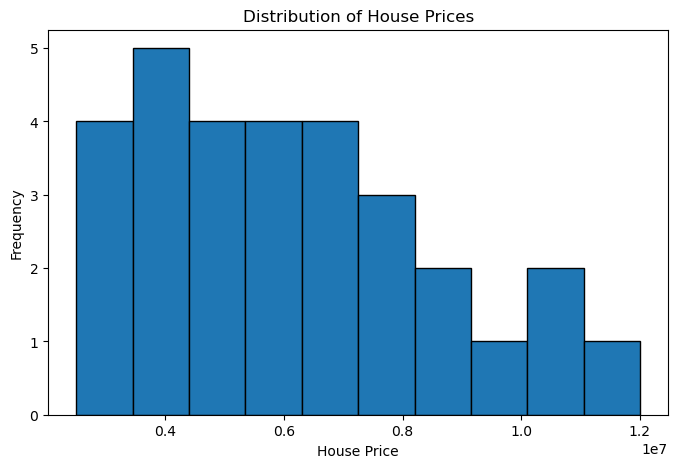

In [7]:
# Visualize house prices

plt.figure(figsize=(8, 5))

plt.hist(df['Price'], bins=10, edgecolor='black')

plt.xlabel('House Price')
plt.ylabel('Frequency')
plt.title('Distribution of House Prices')

plt.show()

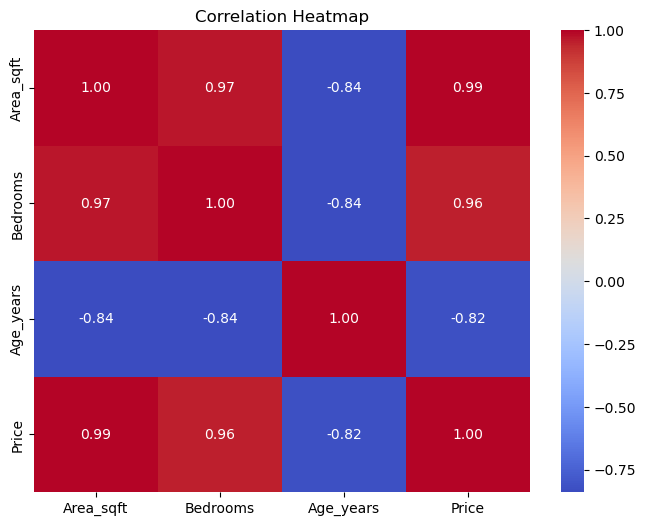

In [8]:
# Correlation heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

In [9]:
# Select independent and dependent variables

X = df[['Area_sqft', 'Bedrooms', 'Age_years']]
y = df['Price']

print("Independent variables:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Independent variables:
   Area_sqft  Bedrooms  Age_years
0       1000         2         10
1       1200         2          8
2       1500         3         12
3       1800         3          5
4       2000         3          7

Target variable:
0    2500000
1    3000000
2    3800000
3    4200000
4    4800000
Name: Price, dtype: int64


In [10]:
# Select a small sample for manual calculation

small_sample = df[['Area_sqft', 'Bedrooms', 'Age_years', 'Price']].head(5)

small_sample

,Area_sqft,Bedrooms,Age_years,Price
0,1000,2,10,2500000
1,1200,2,8,3000000
2,1500,3,12,3800000
3,1800,3,5,4200000
4,2000,3,7,4800000


In [11]:
# Calculate regression coefficients manually

X_small = small_sample[['Area_sqft', 'Bedrooms', 'Age_years']].values
y_small = small_sample['Price'].values

# Add intercept column
X_small_with_intercept = np.column_stack((np.ones(len(X_small)), X_small))

# Calculate coefficients using the matrix formula
beta_manual = np.linalg.inv(X_small_with_intercept.T @ X_small_with_intercept) @ \
              (X_small_with_intercept.T @ y_small)

print("Manually calculated coefficients:")
print("Intercept:", beta_manual[0])
print("Area coefficient:", beta_manual[1])
print("Bedrooms coefficient:", beta_manual[2])
print("Age coefficient:", beta_manual[3])

Manually calculated coefficients:
Intercept: -241379.31034488976
Area coefficient: 2577.5862068965216
Bedrooms coefficient: -150862.06896547973
Age coefficient: 50862.068965524435


In [12]:
# Display the manually calculated regression equation

print("Manual Regression Equation:")
print(f"Price = {beta_manual[0]:.2f} + ({beta_manual[1]:.2f} * Area_sqft) + "
      f"({beta_manual[2]:.2f} * Bedrooms) + ({beta_manual[3]:.2f} * Age_years)")

Manual Regression Equation:
Price = -241379.31 + (2577.59 * Area_sqft) + (-150862.07 * Bedrooms) + (50862.07 * Age_years)


In [13]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

Training data size: (24, 3)
Testing data size: (6, 3)


In [14]:
# Train Multiple Linear Regression model

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully!")

Multiple Linear Regression model trained successfully!


In [15]:
# Display model coefficients

print("Intercept:", multiple_model.intercept_)

for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(f"{feature}: {coefficient}")

Intercept: -413113.60500956327
Area_sqft: 2832.5311232070344
Bedrooms: -160754.40996852447
Age_years: 18285.443501599308


In [16]:
# Display the regression equation

equation = f"Price = {multiple_model.intercept_:.2f}"

for feature, coefficient in zip(X.columns, multiple_model.coef_):
    equation += f" + ({coefficient:.2f} * {feature})"

print("Multiple Linear Regression Equation:")
print(equation)

Multiple Linear Regression Equation:
Price = -413113.61 + (2832.53 * Area_sqft) + (-160754.41 * Bedrooms) + (18285.44 * Age_years)


In [17]:
# Select only Area_sqft as the independent variable

X_single = df[['Area_sqft']]

print(X_single.head())

   Area_sqft
0       1000
1       1200
2       1500
3       1800
4       2000


In [18]:
# Split the single-feature dataset

X_single_train, X_single_test, y_single_train, y_single_test = train_test_split(
    X_single, y, test_size=0.2, random_state=42
)

print("Single-feature training size:", X_single_train.shape)
print("Single-feature testing size:", X_single_test.shape)

Single-feature training size: (24, 1)
Single-feature testing size: (6, 1)


In [19]:
# Train Simple Linear Regression model

simple_model = LinearRegression()

simple_model.fit(X_single_train, y_single_train)

print("Simple Linear Regression model trained successfully!")

Simple Linear Regression model trained successfully!


In [20]:
# Display the simple regression equation

print("Intercept:", simple_model.intercept_)
print("Area coefficient:", simple_model.coef_[0])

print(f"\nSimple Regression Equation:")
print(f"Price = {simple_model.intercept_:.2f} + ({simple_model.coef_[0]:.2f} * Area_sqft)")

Intercept: -302470.9833469661
Area coefficient: 2587.728609462823

Simple Regression Equation:
Price = -302470.98 + (2587.73 * Area_sqft)


In [21]:
# Predict house prices using the multiple regression model

y_pred_multiple = multiple_model.predict(X_test)

prediction_comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_multiple
})

prediction_comparison.head()

,Actual Price,Predicted Price
0,10500000,9.989055e+06
1,5500000,5.550118e+06
2,6400000,6.683130e+06
3,6800000,7.070596e+06
4,7200000,7.335564e+06


In [22]:
# Predict house prices using the simple regression model

y_pred_simple = simple_model.predict(X_single_test)

simple_prediction_comparison = pd.DataFrame({
    'Actual Price': y_single_test.values,
    'Predicted Price': y_pred_simple
})

simple_prediction_comparison.head()

,Actual Price,Predicted Price
0,10500000,1.004844e+07
1,5500000,5.649305e+06
2,6400000,6.684396e+06
3,6800000,7.201942e+06
4,7200000,7.460715e+06


In [23]:
# Create a function to calculate evaluation metrics

def evaluate_model(y_true, y_pred, number_of_features):
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    n = len(y_true)
    p = number_of_features
    
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    
    return mae, rmse, r2, adjusted_r2

In [24]:
# Evaluate Multiple Linear Regression

mae_multiple, rmse_multiple, r2_multiple, adj_r2_multiple = evaluate_model(
    y_test, y_pred_multiple, X.shape[1]
)

print("Multiple Linear Regression Evaluation")
print("-----------------------------------")
print("MAE:", mae_multiple)
print("RMSE:", rmse_multiple)
print("R²:", r2_multiple)
print("Adjusted R²:", adj_r2_multiple)

Multiple Linear Regression Evaluation
-----------------------------------
MAE: 231498.97081997804
RMSE: 275245.41175197467
R²: 0.9692310320300259
Adjusted R²: 0.9230775800750648


In [25]:
# Evaluate Simple Linear Regression

mae_simple, rmse_simple, r2_simple, adj_r2_simple = evaluate_model(
    y_single_test, y_pred_simple, X_single.shape[1]
)

print("Simple Linear Regression Evaluation")
print("-----------------------------------")
print("MAE:", mae_simple)
print("RMSE:", rmse_simple)
print("R²:", r2_simple)
print("Adjusted R²:", adj_r2_simple)

Simple Linear Regression Evaluation
-----------------------------------
MAE: 287695.83703110804
RMSE: 307783.17456303333
R²: 0.961526428569635
Adjusted R²: 0.9519080357120437


In [26]:
# Compare the performance of both models

model_comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MAE': [mae_simple, mae_multiple],
    'RMSE': [rmse_simple, rmse_multiple],
    'R2': [r2_simple, r2_multiple],
    'Adjusted_R2': [adj_r2_simple, adj_r2_multiple]
})

model_comparison

,Model,MAE,RMSE,R2,Adjusted_R2
0,Simple Linear Regression,287695.837031,307783.174563,0.961526,0.951908
1,Multiple Linear Regression,231498.970820,275245.411752,0.969231,0.923078


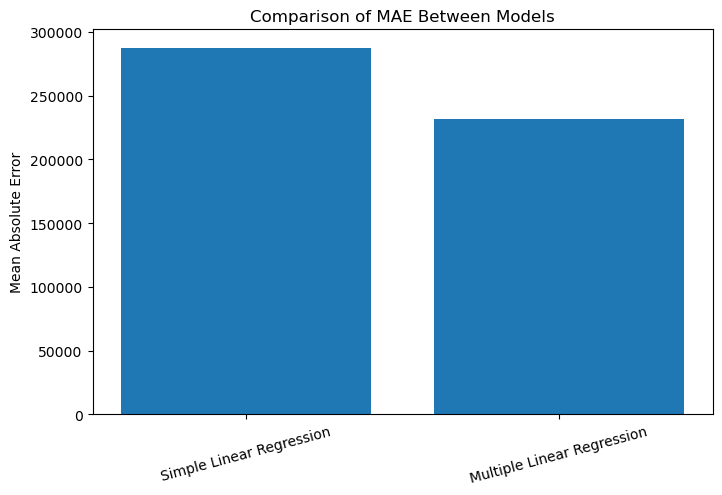

In [27]:
# Compare model performance using MAE

plt.figure(figsize=(8, 5))

plt.bar(model_comparison['Model'], model_comparison['MAE'])

plt.ylabel('Mean Absolute Error')
plt.title('Comparison of MAE Between Models')

plt.xticks(rotation=15)

plt.show()

In [28]:
# Interpret model coefficients

print("Coefficient Interpretation")
print("------------------------")

for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(f"\nFeature: {feature}")
    print(f"Coefficient: {coefficient:.2f}")
    
    if coefficient > 0:
        print(f"As {feature} increases by one unit, predicted house price increases by {coefficient:.2f}, "
              "assuming other features remain constant.")
    elif coefficient < 0:
        print(f"As {feature} increases by one unit, predicted house price decreases by {abs(coefficient):.2f}, "
              "assuming other features remain constant.")
    else:
        print(f"{feature} has no linear effect according to this fitted model.")

Coefficient Interpretation
------------------------

Feature: Area_sqft
Coefficient: 2832.53
As Area_sqft increases by one unit, predicted house price increases by 2832.53, assuming other features remain constant.

Feature: Bedrooms
Coefficient: -160754.41
As Bedrooms increases by one unit, predicted house price decreases by 160754.41, assuming other features remain constant.

Feature: Age_years
Coefficient: 18285.44
As Age_years increases by one unit, predicted house price increases by 18285.44, assuming other features remain constant.


In [29]:
# Calculate Variance Inflation Factor (VIF)

X_vif = sm.add_constant(X)

vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns

vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data

,Feature,VIF
0,const,83.681948
1,Area_sqft,16.057880
2,Bedrooms,16.107381
3,Age_years,3.528119


Interpretation:
- VIF = 1: No multicollinearity.
- VIF between 1 and 5: Moderate correlation may exist.
- VIF above 5: Potential multicollinearity concern.
- VIF above 10: Often considered a stronger warning.
These are general guidelines, not strict rules.

In [30]:
# Calculate residuals

residuals = y_test - y_pred_multiple

residual_data = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_multiple,
    'Residual': residuals.values
})

residual_data.head()

,Actual Price,Predicted Price,Residual
0,10500000,9.989055e+06,510944.684989
1,5500000,5.550118e+06,-50117.556001
2,6400000,6.683130e+06,-283130.005283
3,6800000,7.070596e+06,-270596.376455
4,7200000,7.335564e+06,-135564.045274


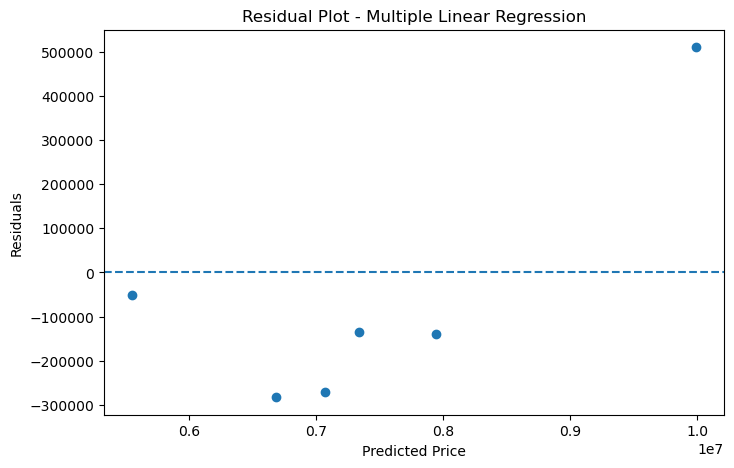

In [31]:
# Plot residuals against predicted values

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_multiple, residuals)

plt.axhline(y=0, linestyle='--')

plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residual Plot - Multiple Linear Regression')

plt.show()

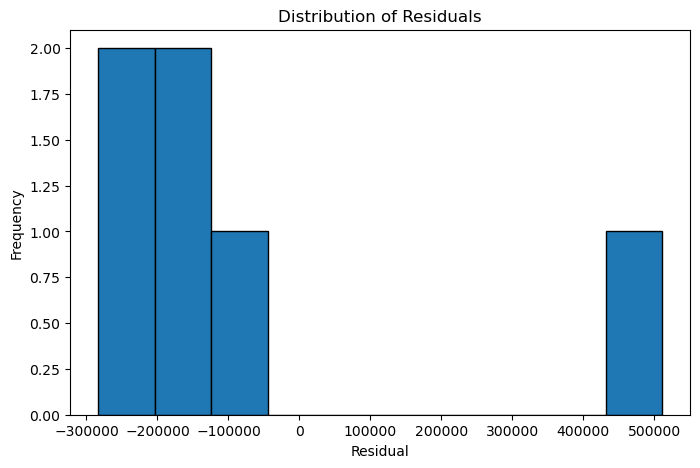

In [32]:
# Plot the residual distribution

plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=10, edgecolor='black')

plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')

plt.show()

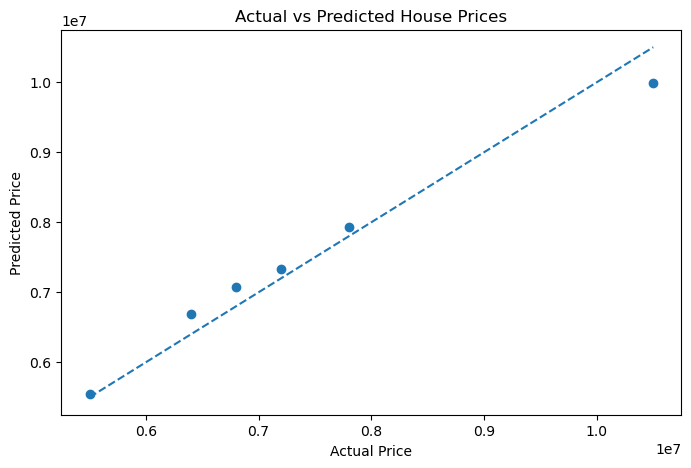

In [33]:
# Visualize actual and predicted house prices

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_multiple)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.show()

In [34]:
# Predict the price of a new house

new_house = pd.DataFrame({
    'Area_sqft': [2500],
    'Bedrooms': [4],
    'Age_years': [5]
})

new_house_prediction = multiple_model.predict(new_house)

print("New House Details:")
print(new_house)

print("\nPredicted House Price:")
print(f"₹{new_house_prediction[0]:,.2f}")

New House Details:
   Area_sqft  Bedrooms  Age_years
0       2500         4          5

Predicted House Price:
₹6,116,623.78


In [35]:
# Final model comparison and conclusion

print("PROJECT CONCLUSION")
print("=================")

if mae_multiple < mae_simple:
    print("Multiple Linear Regression has a lower MAE than Simple Linear Regression.")
    print("The additional features improved prediction accuracy based on MAE.")
elif mae_multiple > mae_simple:
    print("Simple Linear Regression has a lower MAE than Multiple Linear Regression.")
    print("The additional features did not improve prediction accuracy based on MAE.")
else:
    print("Both models have the same MAE.")

print("\nSimple Linear Regression MAE:", mae_simple)
print("Multiple Linear Regression MAE:", mae_multiple)

print("\nSimple Linear Regression R²:", r2_simple)
print("Multiple Linear Regression R²:", r2_multiple)

print("\nThis project demonstrates the use of multiple input features,")
print("manual regression calculations, model training, coefficient interpretation,")
print("multicollinearity analysis, residual analysis, model evaluation,")
print("and prediction of a new house price.")

PROJECT CONCLUSION
Multiple Linear Regression has a lower MAE than Simple Linear Regression.
The additional features improved prediction accuracy based on MAE.

Simple Linear Regression MAE: 287695.83703110804
Multiple Linear Regression MAE: 231498.97081997804

Simple Linear Regression R²: 0.961526428569635
Multiple Linear Regression R²: 0.9692310320300259

This project demonstrates the use of multiple input features,
manual regression calculations, model training, coefficient interpretation,
multicollinearity analysis, residual analysis, model evaluation,
and prediction of a new house price.
